# Machine Learning: Personal Loan Campaign

##Problem Statement

###Business Context

AllLife Bank is a US bank that has a growing customer base. The majority of these customers are liability customers (depositors) with varying sizes of deposits. The number of customers who are also borrowers (asset customers) is quite small, and the bank is interested in expanding this base rapidly to bring in more loan business and in the process, earn more through the interest on loans. In particular, the management wants to explore ways of converting its liability customers to personal loan customers (while retaining them as depositors).

A campaign that the bank ran last year for liability customers showed a healthy conversion rate of over 9% success. This has encouraged the retail marketing department to devise campaigns with better target marketing to increase the success ratio.

You as a Data Scientist at AllLife Bank have to build a model that will help the marketing department to identify the potential customers who have a higher probability of purchasing the loan.

##Objective

To predict whether a liability customer will buy personal loans, to understand which customer attributes are most significant in driving purchases, and to identify which segment of customers to target more.

### Data Dictionary

* ID: Customer ID
* Age: Customer’s age in completed years
* Experience: # years of professional experience
* Income: Annual income of the customer (in thousand dollars)
* ZIP Code: Home Address ZIP code.
* Family: The family size of the customer
* CCAvg: Average spending on credit cards per month (in thousand dollars)
* Education: Education Level. 1: Undergrad; 2: Graduate;3: Advanced/Professional
* Mortgage: Value of house mortgage if any. (in thousand dollars)
* Personal_Loan: Did this customer accept the personal loan offered in the last campaign?
* Securities_Account: Does the customer have a securities account with the bank?
* CD_Account: Does the customer have a certificate of deposit (CD) account with the bank?
* Online: Do customers use Internet banking facilities?
* CreditCard: Does the customer use a credit card issued by any other Bank (excluding All Life Bank)?

### Let us start by importing the required libraries

In [1]:
# Libraries to help with reading and manipulating data
import pandas as pd
import numpy as np

# libaries to help with data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Library to split data
from sklearn.model_selection import train_test_split

# To build model for prediction
from sklearn.tree import DecisionTreeClassifier
from sklearn import tree

# To get diferent metric scores
from sklearn.metrics import (
    f1_score,
    accuracy_score,
    recall_score,
    precision_score,
    confusion_matrix,
)

# To ignore unnecessary warnings
import warnings
warnings.filterwarnings("ignore")

### Understanding the structure of the data

In [2]:
# mount google drive
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [3]:
# Load the dataset from CSV file
data = pd.read_csv("/content/drive/MyDrive/PGP AIML Colab Notebooks/Loan_Modelling.csv")

In [4]:
# Create a working copy of the data for analysis
df = data.copy()

###View the first and last 5 rows of the dataset.

In [5]:
# Display the first 5 rows of the dataset to inspect data
df.head()

,ID,Age,Experience,Income,ZIPCode,Family,CCAvg,Education,Mortgage,Personal_Loan,Securities_Account,CD_Account,Online,CreditCard
0,1,25,1,49,91107,4,1.6,1,0,0,1,0,0,0
1,2,45,19,34,90089,3,1.5,1,0,0,1,0,0,0
2,3,39,15,11,94720,1,1.0,1,0,0,0,0,0,0
3,4,35,9,100,94112,1,2.7,2,0,0,0,0,0,0
4,5,35,8,45,91330,4,1.0,2,0,0,0,0,0,1


In [6]:
# Display the last 5 rows of the dataset to inspect data
df.tail()

,ID,Age,Experience,Income,ZIPCode,Family,CCAvg,Education,Mortgage,Personal_Loan,Securities_Account,CD_Account,Online,CreditCard
4995,4996,29,3,40,92697,1,1.9,3,0,0,0,0,1,0
4996,4997,30,4,15,92037,4,0.4,1,85,0,0,0,1,0
4997,4998,63,39,24,93023,2,0.3,3,0,0,0,0,0,0
4998,4999,65,40,49,90034,3,0.5,2,0,0,0,0,1,0
4999,5000,28,4,83,92612,3,0.8,1,0,0,0,0,1,1


### Rows and Columns in data set

In [7]:
# Check the shape of the dataset (rows, columns)
df.shape

(5000, 14)

#### Observations:
There are 5000 rows and 14 columns

### Check the data types of the columns for the dataset.

In [8]:
# Check the data types of each column in the dataset
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 14 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   ID                  5000 non-null   int64  
 1   Age                 5000 non-null   int64  
 2   Experience          5000 non-null   int64  
 3   Income              5000 non-null   int64  
 4   ZIPCode             5000 non-null   int64  
 5   Family              5000 non-null   int64  
 6   CCAvg               5000 non-null   float64
 7   Education           5000 non-null   int64  
 8   Mortgage            5000 non-null   int64  
 9   Personal_Loan       5000 non-null   int64  
 10  Securities_Account  5000 non-null   int64  
 11  CD_Account          5000 non-null   int64  
 12  Online              5000 non-null   int64  
 13  CreditCard          5000 non-null   int64  
dtypes: float64(1), int64(13)
memory usage: 547.0 KB


#### Observations:
All are numeric data types only.

### Checking for missing values

In [9]:
# Check for missing values in each column
df.isnull().sum()

,0
ID,0
Age,0
Experience,0
Income,0
ZIPCode,0
Family,0
CCAvg,0
Education,0
Mortgage,0
Personal_Loan,0


#### Observations:
There are no missing values in the given data set

### Dropping the duplicate values

In [10]:
# Check for duplicate rows in the dataset
df.duplicated().sum()

np.int64(0)

#### Observations:
There are no duplicates in the given data set

### Statistical Summary of the data

In [11]:
# Get statistical summary for all columns
df.describe().T

,count,mean,std,min,25%,50%,75%,max
ID,5000.0,2500.500000,1443.520003,1.0,1250.75,2500.5,3750.25,5000.0
Age,5000.0,45.338400,11.463166,23.0,35.00,45.0,55.00,67.0
Experience,5000.0,20.104600,11.467954,-3.0,10.00,20.0,30.00,43.0
Income,5000.0,73.774200,46.033729,8.0,39.00,64.0,98.00,224.0
ZIPCode,5000.0,93169.257000,1759.455086,90005.0,91911.00,93437.0,94608.00,96651.0
Family,5000.0,2.396400,1.147663,1.0,1.00,2.0,3.00,4.0
CCAvg,5000.0,1.937938,1.747659,0.0,0.70,1.5,2.50,10.0
Education,5000.0,1.881000,0.839869,1.0,1.00,2.0,3.00,3.0
Mortgage,5000.0,56.498800,101.713802,0.0,0.00,0.0,101.00,635.0
Personal_Loan,5000.0,0.096000,0.294621,0.0,0.00,0.0,0.00,1.0


#### Observations:
* Minimum age of the customer is 23 years and Maximun age is 67 years
* Around 50% of customers has 20 years of professional experience and 25% has 10 years of professional experience. Average experience is approximately 20 years.
* Average income of the customers is $73,000.

* Maximimun income is $224,000.

* Average family is size 2 members.
* 75% of the customer are Advanced/Professionals.
* 75 % of customers has Mortage of $101,000


## Exploratory Data Analysis (EDA) Summary

In [12]:
# Define a function to plot histogram and boxplot together for a feature
def histogram_boxplot(data, feature, figsize=(10,8), kde=False, bins=None):
    """
    Boxplot and histogram combined for a feature
    data: dataframe
    feature: column name
    figsize: size of figure
    kde: show density curve
    bins: number of bins for histogram
    """
    f2, (ax_box2, ax_hist2) = plt.subplots(
        nrows=2,
        sharex=True,
        gridspec_kw={"height_ratios": (0.25, 0.75)},
        figsize=figsize,
    )
    sns.boxplot(data=data, x=feature, ax=ax_box2, showmeans=True, color="violet")
    if bins:
        sns.histplot(data=data, x=feature, kde=kde, ax=ax_hist2, bins=bins)
    else:
        sns.histplot(data=data, x=feature, kde=kde, ax=ax_hist2)

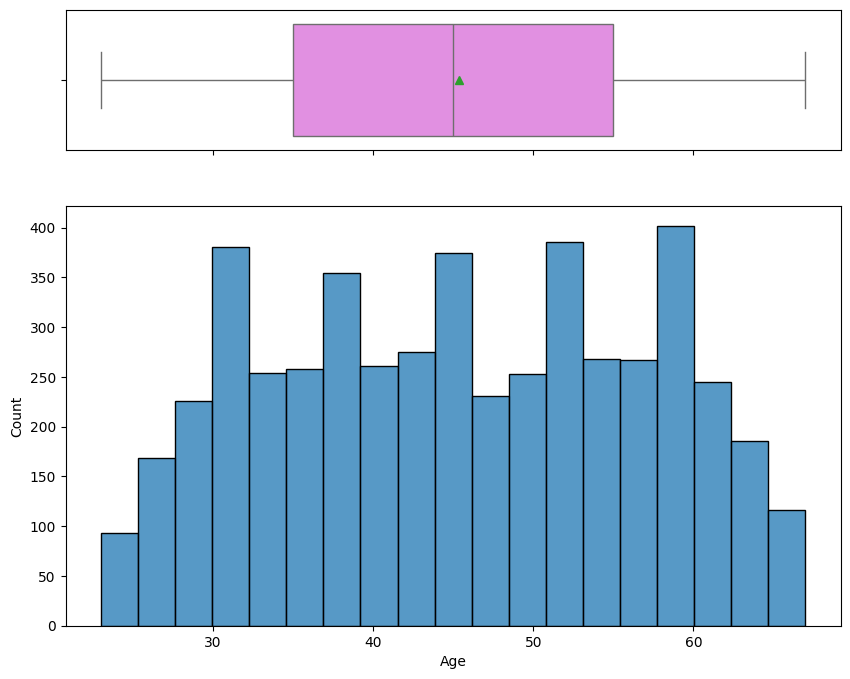

In [13]:
# Example: Plot histogram and boxplot for 'Age' feature
histogram_boxplot(df, "Age")

#### Observations for Age:
* The age distribution appears to be relatively uniform, with a slight peak around the 40-50 age group.
* The minimum age is 23 years, and the maximum age is 67 years.
* The mean age is approximately 45 years, which is also close to the median, indicating a fairly symmetrical distribution.
* There are no apparent outliers in the age distribution.

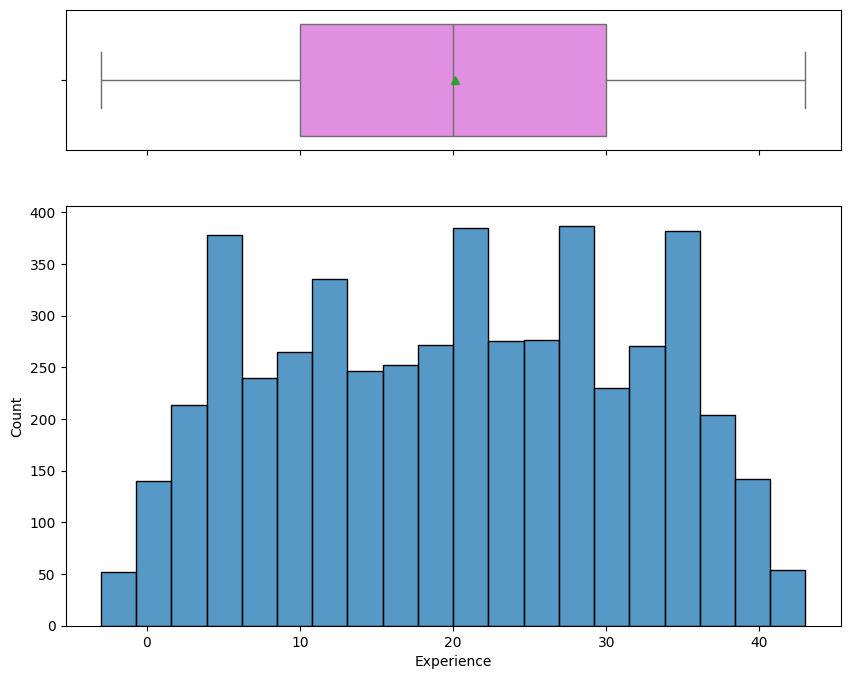

In [14]:
##histogram and box plot for Experience
histogram_boxplot(df, "Experience")

#### Observations for Experience:
* The 'Experience' distribution appears to be relatively symmetrical, centered around 20 years.
* The minimum experience is -3 years, which is unusual and likely a data entry error or an anomaly that should be investigated further.
* The maximum experience is 43 years.
* The mean and median experience are both around 20 years, confirming the central tendency.
* There are no significant outliers beyond the unusual minimum value that would drastically skew the distribution, assuming the negative value is an error.

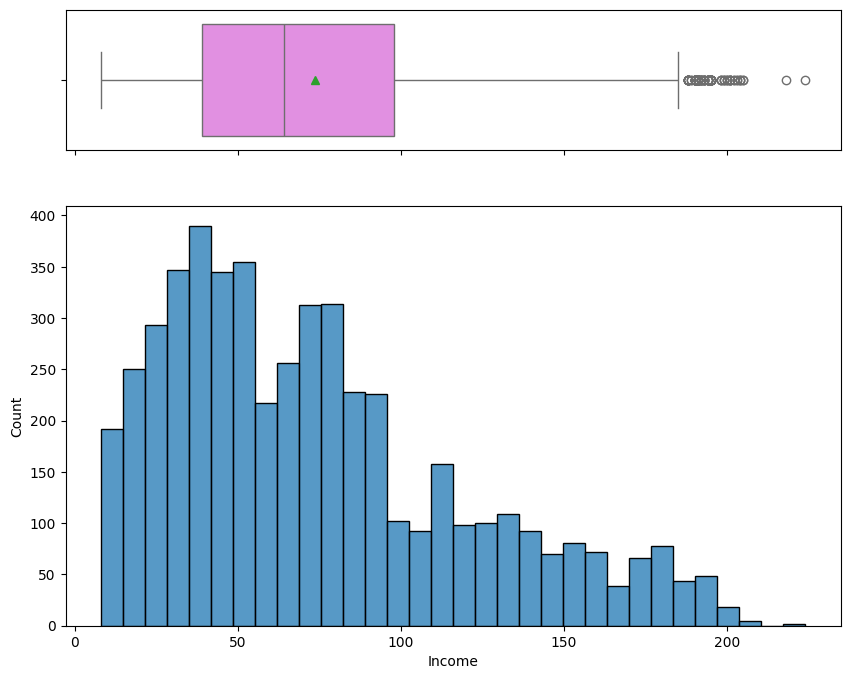

In [15]:
#histogram and box plot for Income
histogram_boxplot(df, "Income")

#### Observations for Income:
* The income distribution is right-skewed, with a majority of customers having lower incomes and a long tail extending towards higher incomes.
* The minimum income is $8,000.

* Maximum income is $224,000.

* The mean income is around $73,000.

* Median is $64,000, which is lower than the mean due to the right-skewness.

* There are several outliers on the higher end of the income scale, indicating some customers with significantly higher incomes than the rest.

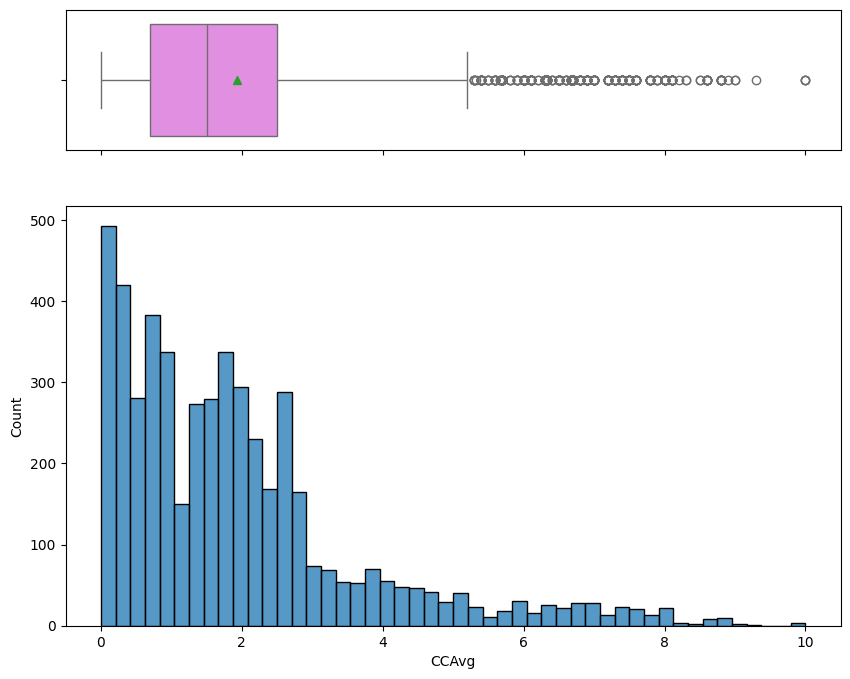

In [16]:
##histogram and box plot for CCAvg
histogram_boxplot(df, "CCAvg")

#### Observations for CCAvg:
* The 'CCAvg' (Average spending on credit cards per month) distribution is heavily right-skewed, indicating that most customers have low credit card spending, with a few customers having significantly higher spending.
* Maximun CCAvg maximum is $10,000.
* There are a considerable number of outliers on the higher end, representing customers with very high credit card usage.

* The mean CCAvg is around $1,937.

* The median CCAvg is $1,500.



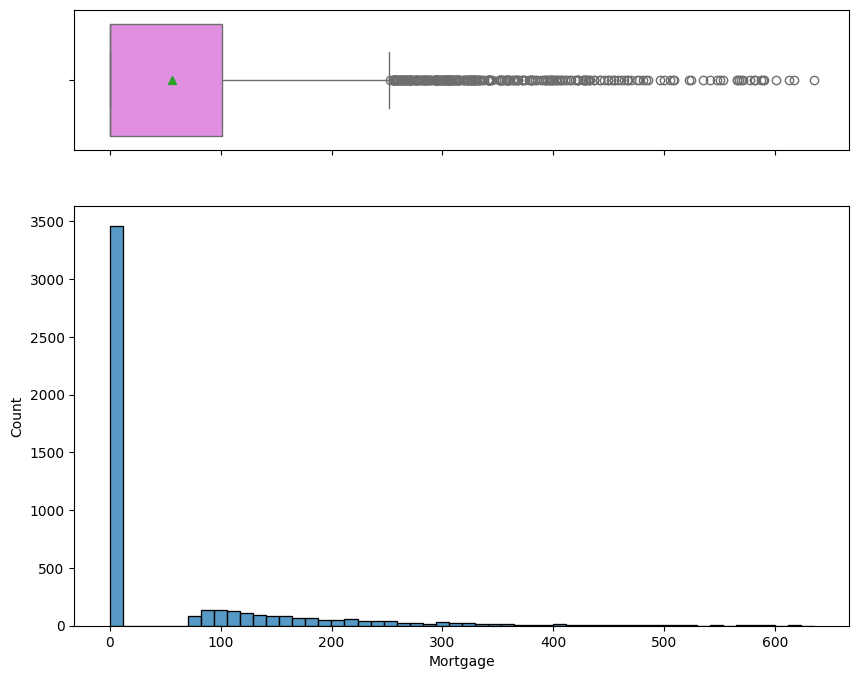

In [17]:
#histogram and boxplot for Mortgage
histogram_boxplot(df, "Mortgage")

#### Observations for Mortgage:
* The 'Mortgage' distribution is also heavily right-skewed, with a large concentration of customers having no mortgage (value of 0).
* Maximum mortgage is $635,000.

* The mean mortgage value is around $56,498.

* Median is $0, clearly indicating that more than half of the customers have no mortgage.
* There are many outliers on the higher end, representing customers with substantial mortgage values. The presence of many zero values suggests that 'Mortgage' might be better analyzed as a categorical variable (has mortgage/no mortgage) in some contexts, in addition to its numerical value.

<Axes: >

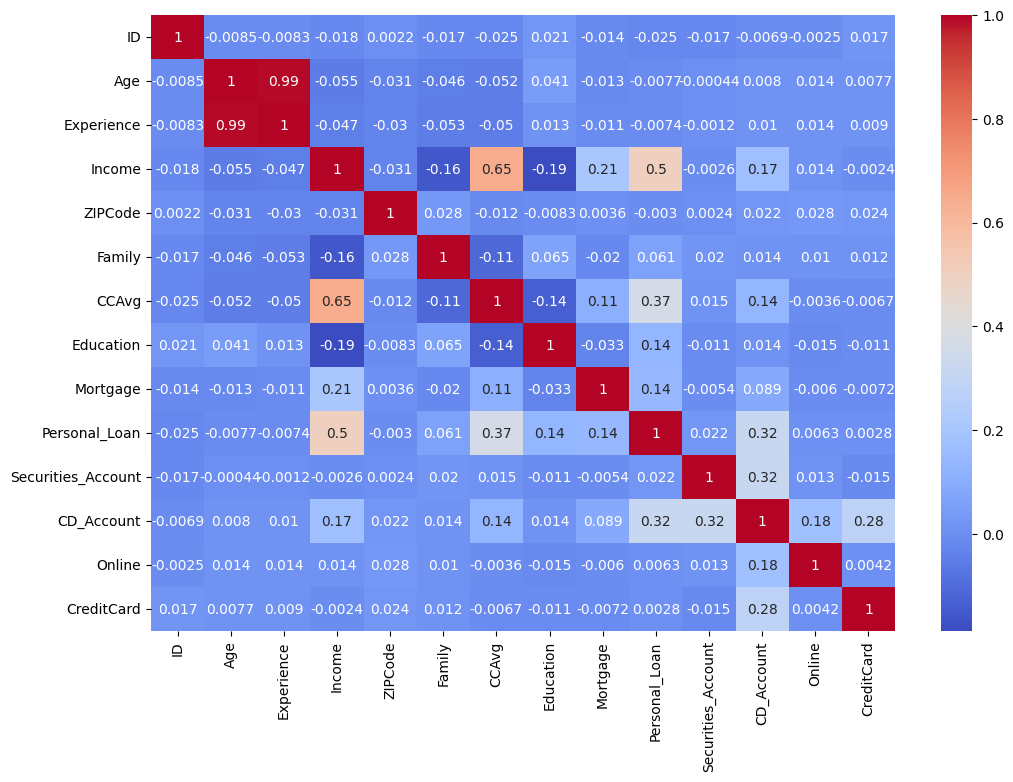

In [18]:
# Plot a heatmap of correlations between all features
plt.figure(figsize=(12, 8))
sns.heatmap(df.corr(),annot=True,cmap="coolwarm")

#### Observations for Heatmap
*   **Positive Correlations with Personal_Loan:**
    *   Income shows the strongest positive correlation with Personal_Loan, indicating that as income increases, the likelihood of taking a personal loan also significantly increases.
    *   CCAvg (Average spending on credit cards) also has a notable positive correlation with Personal_Loan, suggesting that customers who spend more on credit cards are more prone to taking a personal loan.
    *   CD_Account (Certificate of Deposit Account) has a positive correlation with Personal_Loan, implying that customers with CD accounts are more likely to accept a personal loan.

*   **Strong Negative Correlation with Personal_Loan:**
    *   Education has a negative correlation with Personal_Loan. While small, it's worth noting.

*   **Strong Inter-feature Correlations:**
    *   Age and Experience are very highly correlated, which is expected as experience generally increases with age. This suggests that one of these features might be redundant for modeling purposes.
    *   Income and CCAvg have a moderate positive correlation , meaning higher-income customers tend to spend more on credit cards.
    *   Mortgage has a very low correlation with Personal_Loan, suggesting it's not a strong direct predictor.

    

In [19]:
#count plots for categorical data
def countplots_grid(df, cols):
    rows = 1
    cols_len = len(cols)
    cols_per_row = int(np.ceil(cols_len / rows))

    plt.figure(figsize=(cols_per_row * 6, rows * 4))

    for i, col in enumerate(cols, 1):
        plt.subplot(rows, cols_per_row, i)
        sns.countplot(x=df[col], hue=df["Personal_Loan"])
        plt.title(f"Count Plot of {col}")
        plt.xlabel(col)
        plt.ylabel("Count")

    plt.tight_layout()
    plt.show()


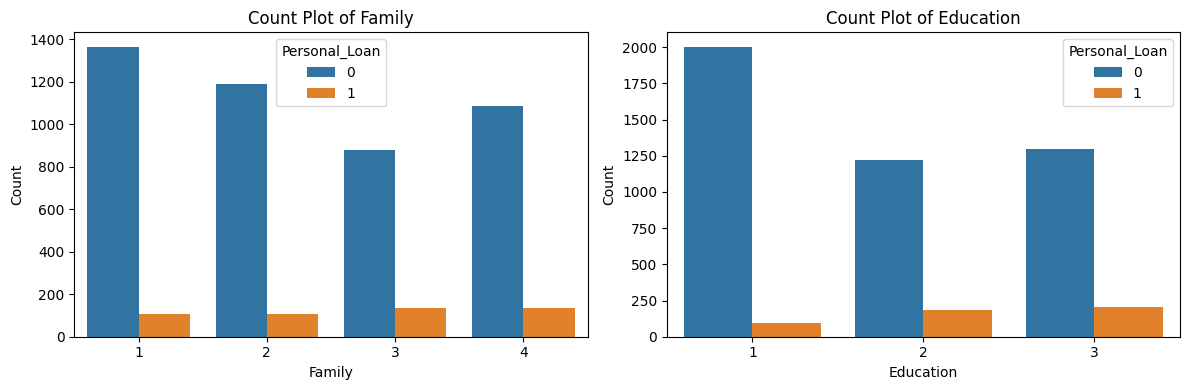

In [20]:
#count plot for family and education
countplots_grid(df, ["Family", "Education"])


#### Detailed Observations for 'Family' and 'Education':
*   **Family:** The distribution of family sizes shows that customers with 1, 2, 3, and 4 members are relatively evenly distributed, with slightly more customers having 1 or 2 family members. When considering 'Personal_Loan', it appears that customers with a family size of 2 or 3 might have a slightly higher propensity to take a personal loan compared to those with 1 or 4 family members, although the overall number of loan takers is small.
*   **Education:** There are more customers with Education Level 1 (Undergrad) and 3 (Advanced/Professional) than Level 2 (Graduate). From the countplot, it seems that customers with Education Level 3 (Advanced/Professional) have a noticeably higher rate of personal loan acceptance compared to those with Education Level 1 or 2. This suggests 'Education' might be an important factor in predicting loan uptake.

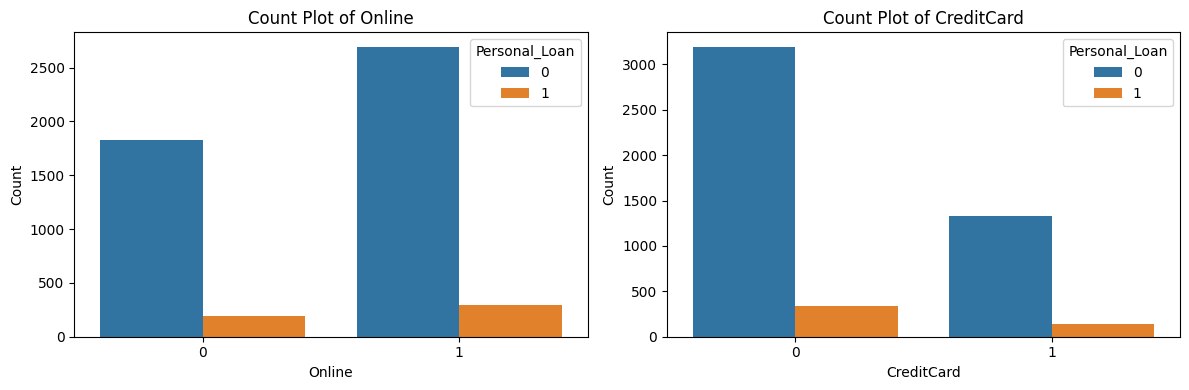

In [21]:
#count plot for online and credi card
countplots_grid(df, ["Online", "CreditCard"])

#### Detailed Observations for 'Online' and 'CreditCard':
*   **Online:** The majority of customers (around 60%) use Internet banking facilities, while a substantial portion (around 40%) do not. When examining personal loan acceptance, there doesn't appear to be a drastic difference in loan uptake between online and non-online users, although the exact proportions would require a more precise calculation.
*   **CreditCard:** Most customers (around 70%) do not use a credit card issued by any other bank, while about 30% do. The countplots suggest that customers who do not use an external credit card might have a slightly higher propensity to take a personal loan, but this difference is not very pronounced.

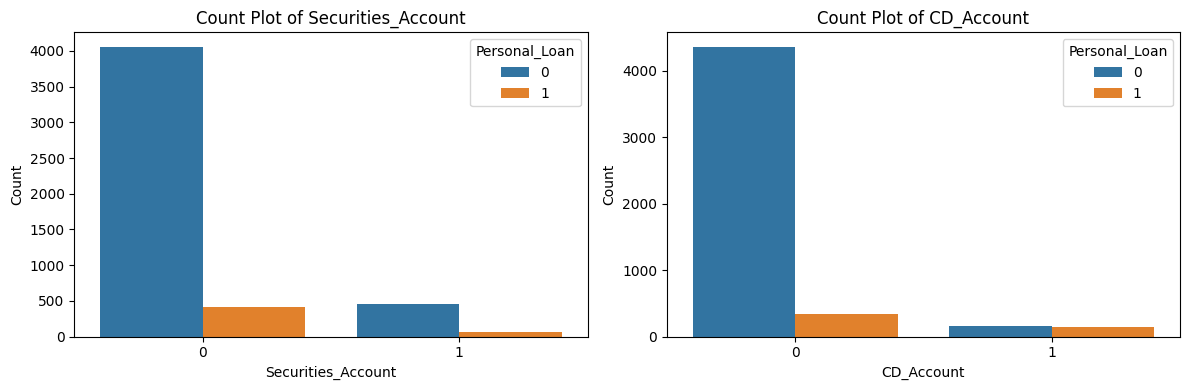

In [22]:
countplots_grid(df, ["Securities_Account",
            "CD_Account"])



#### Detailed Observations for 'Securities_Account' and 'CD_Account':
*   **Securities_Account:** A vast majority of customers (around 90%) do not have a securities account with the bank. The countplot shows that customers with a securities account appear to have a slightly higher proportion of personal loan acceptance compared to those without a securities account, but the absolute numbers of loan takers are low in both groups.
*   **CD_Account:** Similar to securities accounts, most customers (over 90%) do not have a Certificate of Deposit (CD) account. Interestingly, customers who *do* have a CD account show a noticeably higher rate of personal loan acceptance. This suggests that having a CD account could be a stronger indicator for personal loan uptake than having a securities account.

In [23]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 14 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   ID                  5000 non-null   int64  
 1   Age                 5000 non-null   int64  
 2   Experience          5000 non-null   int64  
 3   Income              5000 non-null   int64  
 4   ZIPCode             5000 non-null   int64  
 5   Family              5000 non-null   int64  
 6   CCAvg               5000 non-null   float64
 7   Education           5000 non-null   int64  
 8   Mortgage            5000 non-null   int64  
 9   Personal_Loan       5000 non-null   int64  
 10  Securities_Account  5000 non-null   int64  
 11  CD_Account          5000 non-null   int64  
 12  Online              5000 non-null   int64  
 13  CreditCard          5000 non-null   int64  
dtypes: float64(1), int64(13)
memory usage: 547.0 KB


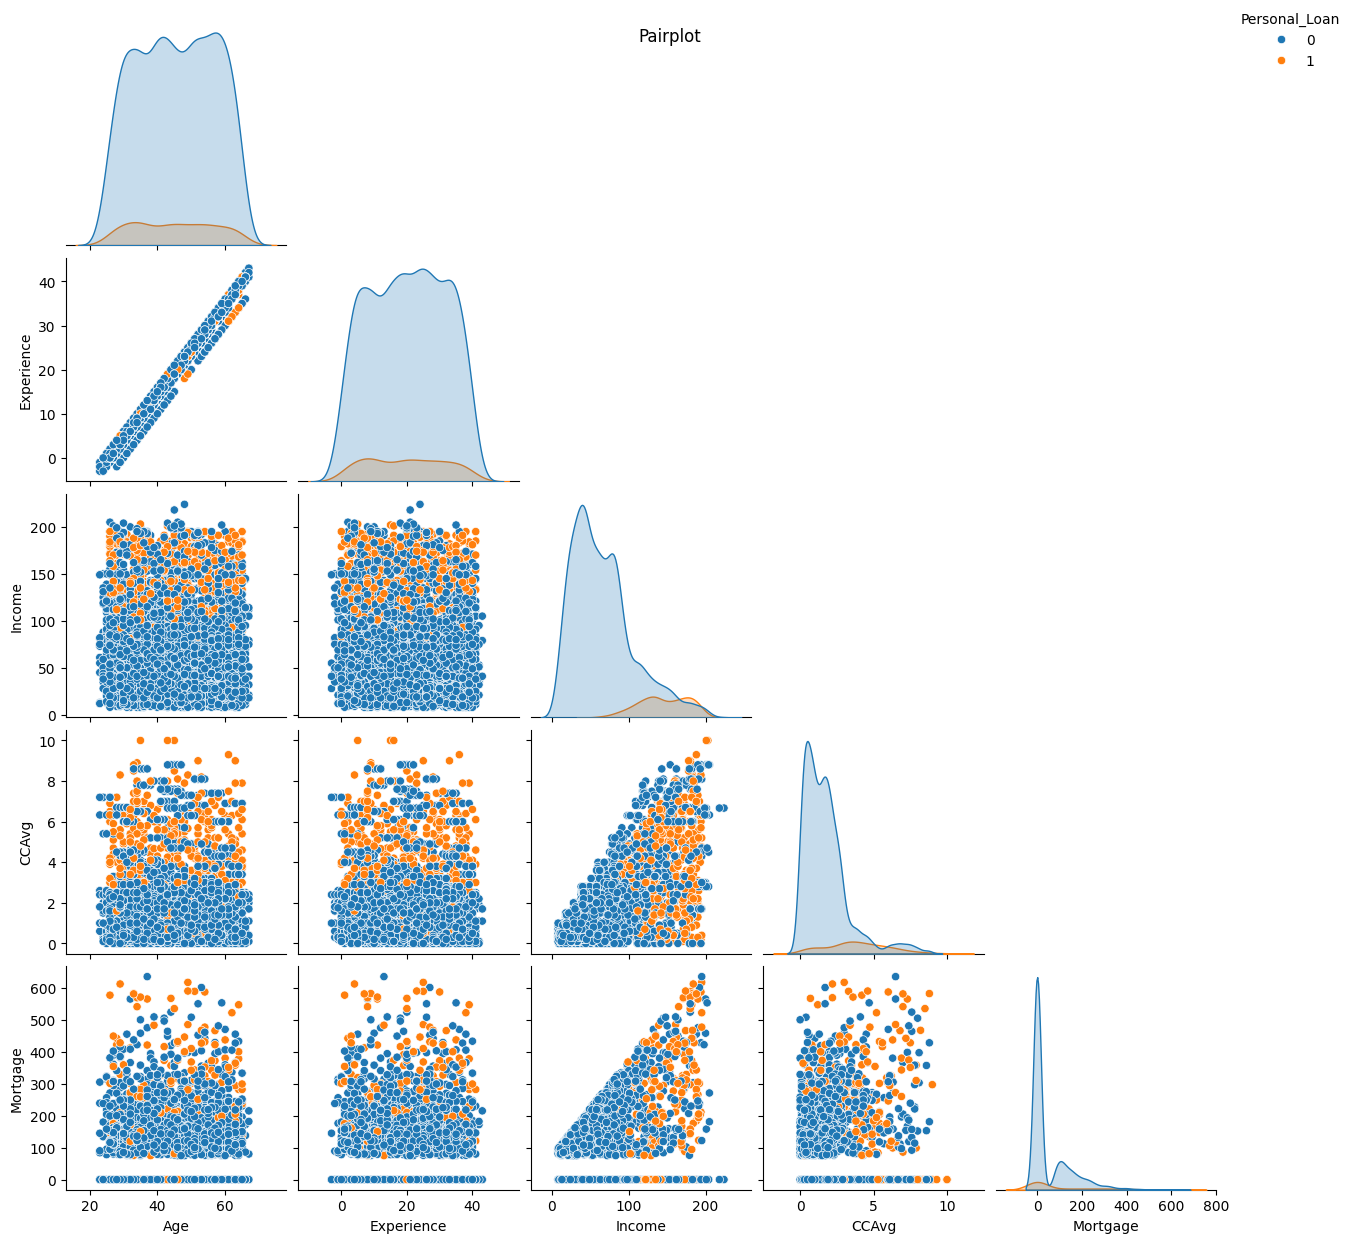

In [24]:
# Create a pair plot for selected numerical columns, colored by day of the week
df_pair_plot = sns.pairplot(df, vars=["Age","Experience","Income","CCAvg","Mortgage"], hue='Personal_Loan',corner=True)
# Set the title
plt.suptitle("Pairplot")
# Position the legend
df_pair_plot._legend.set_loc('upper right')
# Display the plot
plt.show()

###Observations for Pair Plot:

*   **Income is the #1 predictor:** The clearest separation is in Income. People with high income (orange) are much more likely to take a loan than those with low income (blue).
*   **High Spenders take loans:** People who spend more on credit cards (`CCAvg`) also tend to accept loans.
*   **Age doesn't matter:** The orange dots are spread out everywhere for Age. Being young or old doesn't change the likelihood of taking a loan.
*   **Age and Experience are the same:** The plot for `Age` vs. `Experience` is a perfect straight line.

###Decision Tree (Base Model)

###Data Preparation for Modeling


In [25]:
# Select all columns except 'Personal_Loan' as features (X)
X = df.drop(["Personal_Loan"], axis=1)

# Set target variable (Y) as 'Personal_Loan'
Y = data["Personal_Loan"]

# Convert categorical variables to dummy/indicator variables (if any)
X = pd.get_dummies(X, drop_first=True)

# Ensure all features are float type
X = X.astype(float)

# Split data into training and test sets (70% train, 30% test)
X_train, X_test, y_train, y_test = train_test_split(
    X, Y, test_size=0.30, random_state=18
)

In [26]:
print("Shape of Training set : ", X_train.shape)
print("Shape of test set : ", X_test.shape)
print("Percentage of classes in training set:")
print(y_train.value_counts(normalize=True))
print("Percentage of classes in test set:")
print(y_test.value_counts(normalize=True))

Shape of Training set :  (3500, 13)
Shape of test set :  (1500, 13)
Percentage of classes in training set:
Personal_Loan
0    0.903143
1    0.096857
Name: proportion, dtype: float64
Percentage of classes in test set:
Personal_Loan
0    0.906
1    0.094
Name: proportion, dtype: float64


###Model Evaluation Criterion


- At AllLife Bank, the predictive model can make two types of errors:
    - **False Negatives**: The model predicts a customer will not take a personal loan, but the customer actually would have.
    - **False Positives**: The model predicts a customer will take a loan, but the customer does not.

- **False Negatives are more costly** because:
    - The bank loses potential interest income.
    - Misses opportunities to convert liability customers into personal loan customers (a key strategic goal).

- **False Positives** mainly result in minor marketing costs (contacting uninterested customers).

- **Recommendation**: The bank should focus on maximizing **recall** to minimize False Negatives, ensuring more genuinely interested customers are identified and increasing the success of the marketing campaign.

In [27]:
# Function to compute classification metrics for a sklearn model
def model_performance_classification_sklearn(model, predictors, target):
    """
    Compute accuracy, recall, precision, and F1 score for a classification model.

    model: trained classifier
    predictors: feature set
    target: true labels
    """
    # Predict labels
    pred = model.predict(predictors)

    # Calculate metrics
    acc = accuracy_score(target, pred)
    recall = recall_score(target, pred)
    precision = precision_score(target, pred)
    f1 = f1_score(target, pred)

    # Create a DataFrame with the results
    df_perf = pd.DataFrame(
        {
            "Accuracy": acc,
            "Recall": recall,
            "Precision": precision,
            "F1": f1,
        },
        index=[0],
    )

    return df_perf

In [28]:
#define confusion matrix with required details
def confusion_matrix_sklearn(model, predictors, target):
    """
    Plot the confusion matrix with percentages.

    model: trained classifier
    predictors: feature set
    target: true labels
    """
    # Predict the labels for the given predictors
    y_pred = model.predict(predictors)

    # Compute the confusion matrix
    cm = confusion_matrix(target, y_pred)

    # Create labels with counts and percentages for each cell
    labels = np.asarray(
        [
            [f"{item:.0f}\n{item / cm.sum():.2%}"]
            for item in cm.flatten()
        ]
    ).reshape(2, 2)

    # Plot the confusion matrix as a heatmap
    plt.figure(figsize=(6, 4))
    sns.heatmap(cm, annot=labels, fmt="")
    plt.ylabel("True label")
    plt.xlabel("Predicted label")

In [29]:
# Instantiate a Decision Tree Classifier with a fixed random state for reproducibility
model0 = DecisionTreeClassifier(random_state=7)

# Fit the model to the training data
model0.fit(X_train, y_train)

DecisionTreeClassifier(random_state=7)

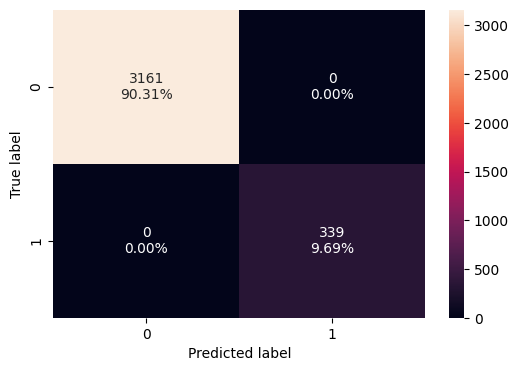

In [30]:
# Plot confusion matrix for the default Decision Tree (model0) on the training set.
# This visualizes True Negatives, False Positives, False Negatives and True Positives
# (with counts and percentages) so we can inspect how the model performs on training data.
confusion_matrix_sklearn(model0, X_train, y_train)

###Observations:-
The model classified every customer correctly with no misclassifications, achieving perfect accuracy on this dataset.

In [31]:
# Evaluate default Decision Tree (model0) on the training set.
# Uses the helper function to compute Accuracy, Recall, Precision and F1.
decision_tree_default_perf_train = model_performance_classification_sklearn(
    model0, X_train, y_train
)

# Show the training performance DataFrame
decision_tree_default_perf_train

,Accuracy,Recall,Precision,F1
0,1.0,1.0,1.0,1.0


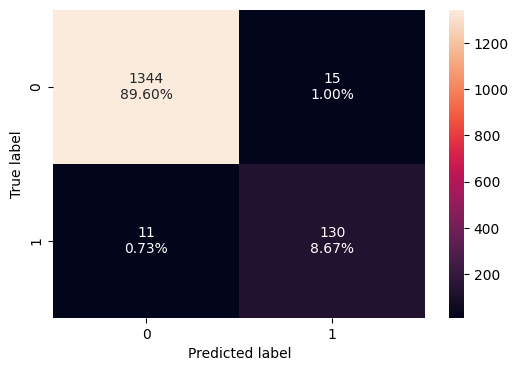

In [32]:
# Plot confusion matrix for the default Decision Tree (model0) on the test set.
# Shows counts and percentages for:
#   TN (top-left), FP (top-right), FN (bottom-left), TP (bottom-right).
# Note: FN (bottom-left) is most costly for the business (missed loan takers),
# so inspect that cell closely to evaluate model risk.
confusion_matrix_sklearn(model0, X_test, y_test)


###Observations:-
The model makes a few mistakes but correctly identifies most customers, with good recall and only small numbers of false positives and false negatives.

In [33]:
# Evaluate the default Decision Tree (model0) on the test set.
# We focus on recall as the business metric (minimize false negatives).
decision_tree_default_perf_test = model_performance_classification_sklearn(
    model0, X_test, y_test
)

# Display the performance metrics for the test set
decision_tree_default_perf_test

,Accuracy,Recall,Precision,F1
0,0.982667,0.921986,0.896552,0.909091


###Decision Tree (with class_weights)


If the frequency of class A is 10% and the frequency of class B is 90%, then class B will become the dominant class and the decision tree will become biased toward the dominant classes

In this case, we will set class_weight = "balanced", which will automatically adjust the weights to be inversely proportional to the class frequencies in the input data

class_weight is a hyperparameter for the decision tree classifier

In [34]:
# Instantiate Decision Tree classifier with balanced class weights to handle class imbalance
# random_state ensures reproducible results
model1 = DecisionTreeClassifier(random_state=1, class_weight="balanced")

# Train (fit) the model on the training data (X_train features and y_train labels)
model1.fit(X_train, y_train)

DecisionTreeClassifier(class_weight='balanced', random_state=1)

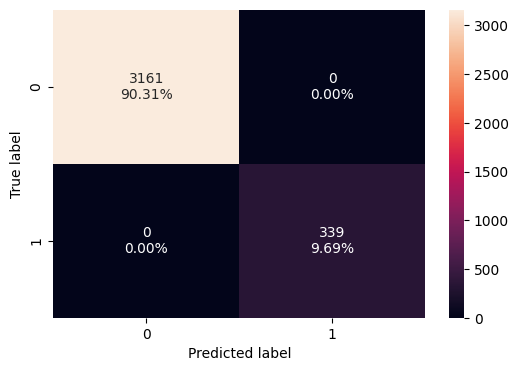

In [35]:
# Plot confusion matrix for model1 (DecisionTree with class_weight='balanced')
# This visualizes:
#   - True Negatives (top-left), False Positives (top-right)
#   - False Negatives (bottom-left), True Positives (bottom-right)
# Counts and percentages are shown for each cell.
# Note: For this business problem, False Negatives (bottom-left) are most costly.
confusion_matrix_sklearn(model1, X_train, y_train)

###Observations:-
The model made no errors, correctly predicting all classes with perfect accuracy.

In [36]:
# Evaluate the Decision Tree with class_weight='balanced' on the training set.
# Note: Recall is the business-priority metric (minimize false negatives).
decision_tree_perf_train = model_performance_classification_sklearn(
    model1, X_train, y_train
)

# Display the computed performance metrics for the training set
decision_tree_perf_train

,Accuracy,Recall,Precision,F1
0,1.0,1.0,1.0,1.0


Model is able to perfectly classify all the data points on the training set.
0 errors on the training set, each sample has been classified correctly.
As we know a decision tree will continue to grow and classify each data point correctly if no restrictions are applied as the trees will learn all the patterns in the training set.
This generally leads to overfitting of the model as Decision Tree will perform well on the training set but will fail to replicate the performance on the test set.

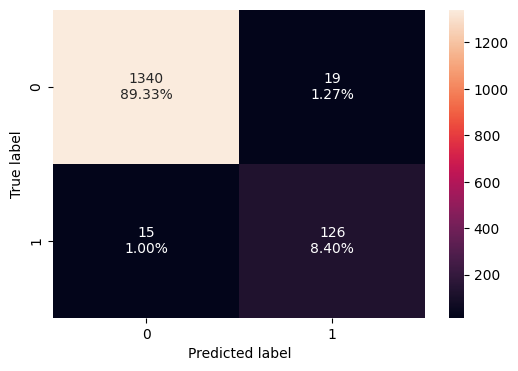

In [37]:
# Plot confusion matrix for model1 (DecisionTree with class_weight='balanced') on the test set.
# The heatmap displays:
#   - Top-left: True Negatives (TN)
#   - Top-right: False Positives (FP)
#   - Bottom-left: False Negatives (FN)
#   - Bottom-right: True Positives (TP)
# Inspect the FN cell closely because a high FN means missed potential loan customers.
confusion_matrix_sklearn(model1, X_test, y_test)

###Observations:-
The model makes some mistakes but still correctly predicts most customers overall.

In [38]:
# Evaluate the Decision Tree (model1: class_weight='balanced') on the test set.
decision_tree_perf_test = model_performance_classification_sklearn(
    model1, X_test, y_test
)

# Show the performance metrics for the test set
decision_tree_perf_test

,Accuracy,Recall,Precision,F1
0,0.977333,0.893617,0.868966,0.881119


###Decision Tree (Pre-pruning)

Hyperparameter tuning is crucial because it directly affects the performance of a model.
Unlike model parameters which are learned during training, hyperparameters need to be set before training.
Effective hyperparameter tuning helps in improving the performance and robustness of the model.
The below custom loop for hyperparameter tuning iterates over predefined parameter values to identify the best model based on the metric of choice (recall score).

In [39]:
# Define the parameters of the tree to iterate over
max_depth_values = np.arange(2, 10)
max_leaf_nodes_values = [50, 75, 150, 250,300]
min_samples_split_values = [10, 20, 30, 50, 70, 100]

# Initialize variables to store the best model and its performance
best_estimator = None
best_score_diff = float('inf')
best_test_score = 0.0

# Iterate over all combinations of the specified parameter values
for max_depth in max_depth_values:
    for max_leaf_nodes in max_leaf_nodes_values:
        for min_samples_split in min_samples_split_values:

            # Initialize the tree with the current set of parameters
            estimator = DecisionTreeClassifier(
                max_depth=max_depth,
                max_leaf_nodes=max_leaf_nodes,
                min_samples_split=min_samples_split,
                class_weight='balanced',
                random_state=42
            )

            # Fit the model to the training data
            estimator.fit(X_train, y_train)

            # Make predictions on the training and test sets
            y_train_pred = estimator.predict(X_train)
            y_test_pred = estimator.predict(X_test)

            # Calculate recall scores for training and test sets
            train_recall_score = recall_score(y_train, y_train_pred)
            test_recall_score = recall_score(y_test, y_test_pred)

            # Calculate the absolute difference between training and test recall scores
            score_diff = abs(train_recall_score - test_recall_score)

            # Update the best estimator and best score if the current one has a smaller score difference
            if (score_diff < best_score_diff) & (test_recall_score > best_test_score):
                best_score_diff = score_diff
                best_test_score = test_recall_score
                best_estimator = estimator

# Print the best parameters
print("Best parameters found:")
print(f"Max depth: {best_estimator.max_depth}")
print(f"Max leaf nodes: {best_estimator.max_leaf_nodes}")
print(f"Min samples split: {best_estimator.min_samples_split}")
print(f"Best test recall score: {best_test_score}")

Best parameters found:
Max depth: 4
Max leaf nodes: 50
Min samples split: 10
Best test recall score: 0.9645390070921985


In [40]:
# creating an instance of the best model
model2 = best_estimator

# fitting the best model to the training data
model2.fit(X_train, y_train)

DecisionTreeClassifier(class_weight='balanced', max_depth=np.int64(4),
                       max_leaf_nodes=50, min_samples_split=10,
                       random_state=42)

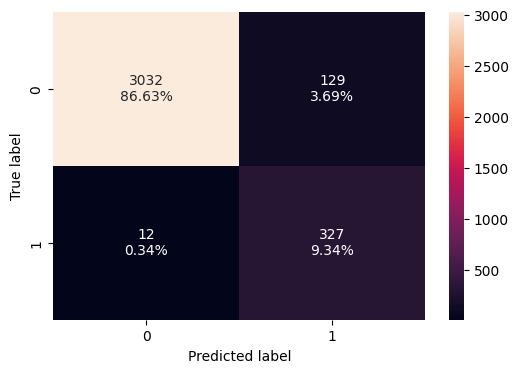

In [41]:
# Plot confusion matrix for the tuned Decision Tree (model2) on the training set.
# Shows counts and percentages for:
#   TN (top-left), FP (top-right), FN (bottom-left), TP (bottom-right).
# Note: FN (bottom-left) is the most costly for the business (missed potential loan takers).
# Use this plot to inspect whether the tuned model is under-predicting the positive class.
confusion_matrix_sklearn(model2, X_train, y_train)

In [42]:
# Evaluate the tuned Decision Tree (model2) on the training set.
# This uses the helper function to compute accuracy, recall, precision and F1.
# Recall is the business-priority metric (minimize false negatives).
decision_tree_tune_perf_train = model_performance_classification_sklearn(
    model2, X_train, y_train
)

# Display the training performance metrics
decision_tree_tune_perf_train

,Accuracy,Recall,Precision,F1
0,0.959714,0.964602,0.717105,0.822642


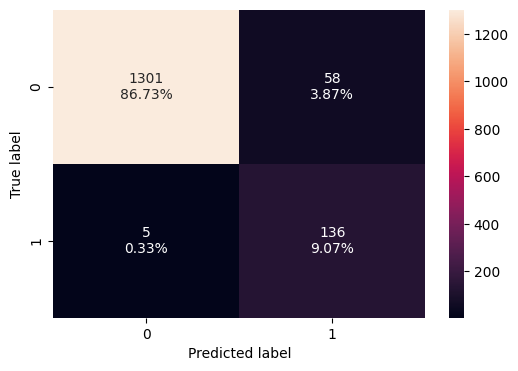

In [43]:
# Plot confusion matrix for the tuned Decision Tree (model2) on the TEST set.
# This shows:
#   - Top-left: True Negatives (TN)
#   - Top-right: False Positives (FP)
#   - Bottom-left: False Negatives (FN)
#   - Bottom-right: True Positives (TP)
# Counts and percentages are displayed in each cell to help assess model risk.
confusion_matrix_sklearn(model2, X_test, y_test)

In [44]:
# Compute performance metrics for the tuned Decision Tree (model2) on the test set.
# The helper `model_performance_classification_sklearn` returns a DataFrame with
# Accuracy, Recall, Precision and F1 score.
decision_tree_tune_perf_test = model_performance_classification_sklearn(
    model2, X_test, y_test
)

# Display the performance DataFrame (Accuracy, Recall, Precision, F1).
# Note: Recall is the business-priority metric (minimize false negatives).
decision_tree_tune_perf_test

,Accuracy,Recall,Precision,F1
0,0.958,0.964539,0.701031,0.81194


In [45]:
# Get the feature names from the training DataFrame (order matches model input)
feature_names = list(X_train.columns)

# Retrieve feature importances from the trained tuned decision tree (model2)
importances = model2.feature_importances_

# Get indices that would sort importances (ascending) — useful for ordered plotting
indices = np.argsort(importances)

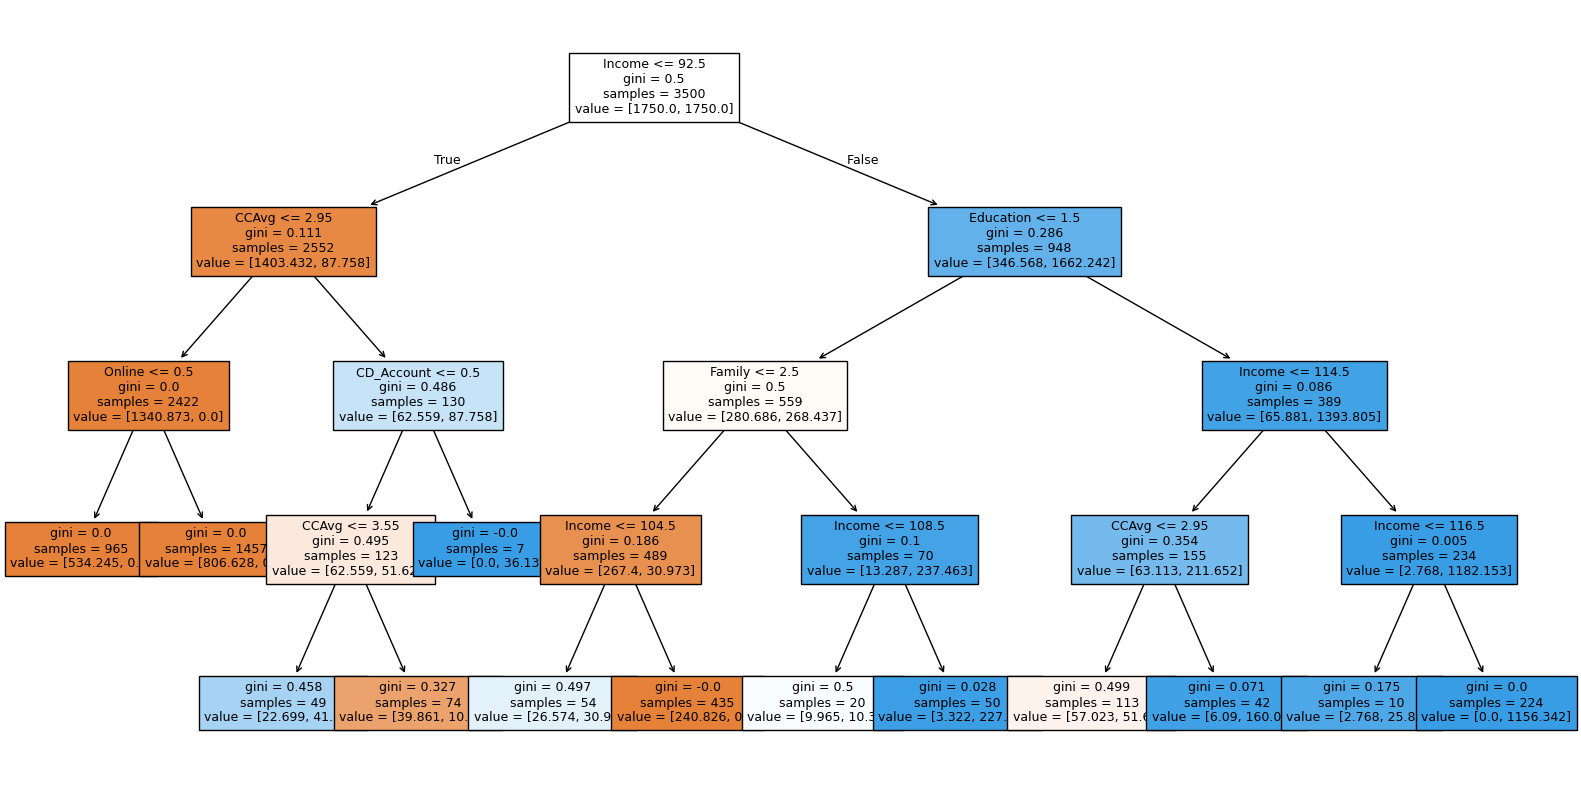

In [46]:
# Create a large figure for the tree so text is readable
plt.figure(figsize=(20, 10))

# Plot the decision tree; returns a list of text/artist objects (node labels)
out = tree.plot_tree(
    model2,
    feature_names=feature_names,  # use the training feature order for labels
    filled=True,                  # color nodes by class
    fontsize=9,                   # font size for node text
    node_ids=False,               # don't annotate nodes with numeric ids
    class_names=None,             # let sklearn display class labels (0/1) by default
)

# Some backends/versions may omit arrow styling; ensure arrows (if present) are visible
for o in out:
    # each returned object may have an `arrow_patch` attribute for split connectors
    arrow = getattr(o, "arrow_patch", None)
    if arrow is not None:
        # make the arrow edges clearly visible
        arrow.set_edgecolor("black")
        arrow.set_linewidth(1)

# Render the plotted tree in the notebook output
plt.show()

In [47]:
# Print a textual representation of the trained decision tree (model2).
print(tree.export_text(model2, feature_names=feature_names, show_weights=True))


|--- Income <= 92.50
|   |--- CCAvg <= 2.95
|   |   |--- Online <= 0.50
|   |   |   |--- weights: [534.25, 0.00] class: 0
|   |   |--- Online >  0.50
|   |   |   |--- weights: [806.63, 0.00] class: 0
|   |--- CCAvg >  2.95
|   |   |--- CD_Account <= 0.50
|   |   |   |--- CCAvg <= 3.55
|   |   |   |   |--- weights: [22.70, 41.30] class: 1
|   |   |   |--- CCAvg >  3.55
|   |   |   |   |--- weights: [39.86, 10.32] class: 0
|   |   |--- CD_Account >  0.50
|   |   |   |--- weights: [0.00, 36.14] class: 1
|--- Income >  92.50
|   |--- Education <= 1.50
|   |   |--- Family <= 2.50
|   |   |   |--- Income <= 104.50
|   |   |   |   |--- weights: [26.57, 30.97] class: 1
|   |   |   |--- Income >  104.50
|   |   |   |   |--- weights: [240.83, 0.00] class: 0
|   |   |--- Family >  2.50
|   |   |   |--- Income <= 108.50
|   |   |   |   |--- weights: [9.97, 10.32] class: 1
|   |   |   |--- Income >  108.50
|   |   |   |   |--- weights: [3.32, 227.14] class: 1
|   |--- Education >  1.50
|   |   |---

In [48]:
# Retrieve feature importances from the tuned decision tree (model2).
importances = model2.feature_importances_
# Display the raw importances array
importances

array([0.00000000e+00, 0.00000000e+00, 0.00000000e+00, 6.73911850e-01,
       0.00000000e+00, 1.21997602e-01, 8.45806191e-02, 1.09132970e-01,
       0.00000000e+00, 0.00000000e+00, 1.03769586e-02, 8.99901218e-15,
       0.00000000e+00])

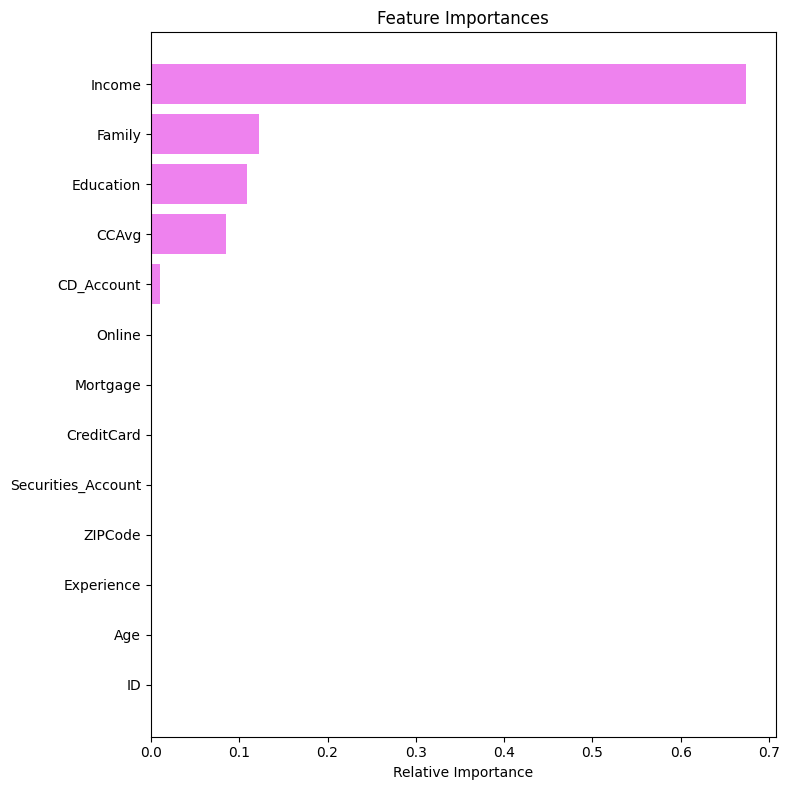

In [49]:
# Plot horizontal bar chart of feature importances from the tuned decision tree (model2)
# importances: numpy array of feature importances (aligned with feature_names)
# indices: order of feature indices sorted by importance (ascending)

# Recompute indices to ensure they match current importances (safe no-op if already correct)
indices = np.argsort(importances)

plt.figure(figsize=(8, 8))
plt.title("Feature Importances")

# Plot horizontal bars: smallest importance at the top, largest at the bottom
plt.barh(range(len(indices)), importances[indices], color="violet", align="center")

# Label y-ticks with feature names in the same sorted order
plt.yticks(range(len(indices)), [feature_names[i] for i in indices])

# Label x-axis and tighten layout for readability
plt.xlabel("Relative Importance")
plt.tight_layout()
plt.show()

###Decision Tree (Post pruning)

**Total impurity of leaves vs effective alphas of pruned tree**

In [50]:
# Instantiate a DecisionTreeClassifier with balanced class weights to handle class imbalance
clf = DecisionTreeClassifier(random_state=1, class_weight="balanced")

# Compute the cost-complexity pruning path on the training data.
# This returns a Bunch with `ccp_alphas` (effective alphas) and `impurities` (total impurity of leaves).
path = clf.cost_complexity_pruning_path(X_train, y_train)

# Extract alphas and impurities. Use abs() on alphas to guard against tiny negative rounding artifacts.
ccp_alphas, impurities = abs(path.ccp_alphas), path.impurities

In [51]:
# Convert the pruning path (a Bunch with 'ccp_alphas' and 'impurities') to a DataFrame
# This makes it easier to inspect and manipulate the effective alphas and corresponding impurities.
# `path` was obtained from clf.cost_complexity_pruning_path(X_train, y_train)
pruning_df = pd.DataFrame(path)

# Show the first few rows to verify contents (ccp_alphas and impurities)
pruning_df.head()

,ccp_alphas,impurities
0,0.000000e+00,-1.436408e-16
1,1.053676e-19,-1.435354e-16
2,1.053676e-19,-1.434300e-16
3,2.107352e-19,-1.432193e-16
4,2.107352e-19,-1.430086e-16


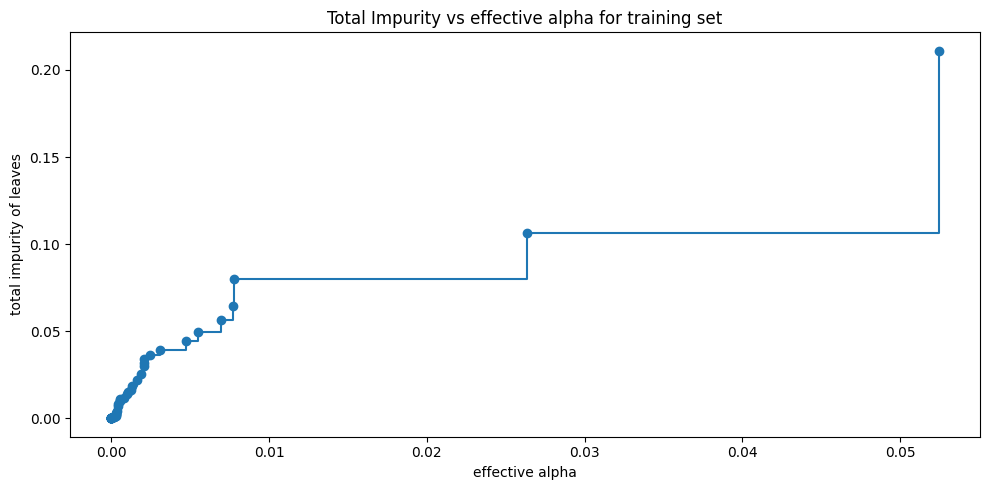

In [52]:
# Create a figure and axis for the plot (10x5 inches)
fig, ax = plt.subplots(figsize=(10, 5))

# Plot total impurity of leaves vs effective alpha.
# Exclude the last alpha/impurity pair because the final alpha often collapses the tree to a single node.
ax.plot(ccp_alphas[:-1], impurities[:-1], marker="o", drawstyle="steps-post")

# Axis labels and title
ax.set_xlabel("effective alpha")                # complexity parameter for pruning
ax.set_ylabel("total impurity of leaves")       # sum of impurities for leaves at given alpha
ax.set_title("Total Impurity vs effective alpha for training set")

# Tighten layout and show plot
plt.tight_layout()
plt.show()

In [53]:
# Create an empty list to store decision tree classifiers trained for each ccp_alpha
clfs = []

# Iterate over all effective alphas obtained from the cost-complexity pruning path
for ccp_alpha in ccp_alphas:
    # Instantiate a DecisionTreeClassifier with the current ccp_alpha.
    # class_weight='balanced' keeps handling of class imbalance consistent.
    # random_state=1 ensures results are reproducible.
    clf = DecisionTreeClassifier(
        random_state=1, ccp_alpha=ccp_alpha, class_weight="balanced"
    )

    # Fit the classifier on the training data (X_train, y_train)
    clf.fit(X_train, y_train)

    # Append the fitted classifier to the list for later inspection/analysis
    clfs.append(clf)

# Print the number of nodes in the last trained tree and the corresponding ccp_alpha.
# The last alpha typically corresponds to the largest pruning (often collapsing the tree).
print(
    "Number of nodes in the last tree is: {} with ccp_alpha: {}".format(
        clfs[-1].tree_.node_count, ccp_alphas[-1]
    )
)

Number of nodes in the last tree is: 1 with ccp_alpha: 0.288931525393286


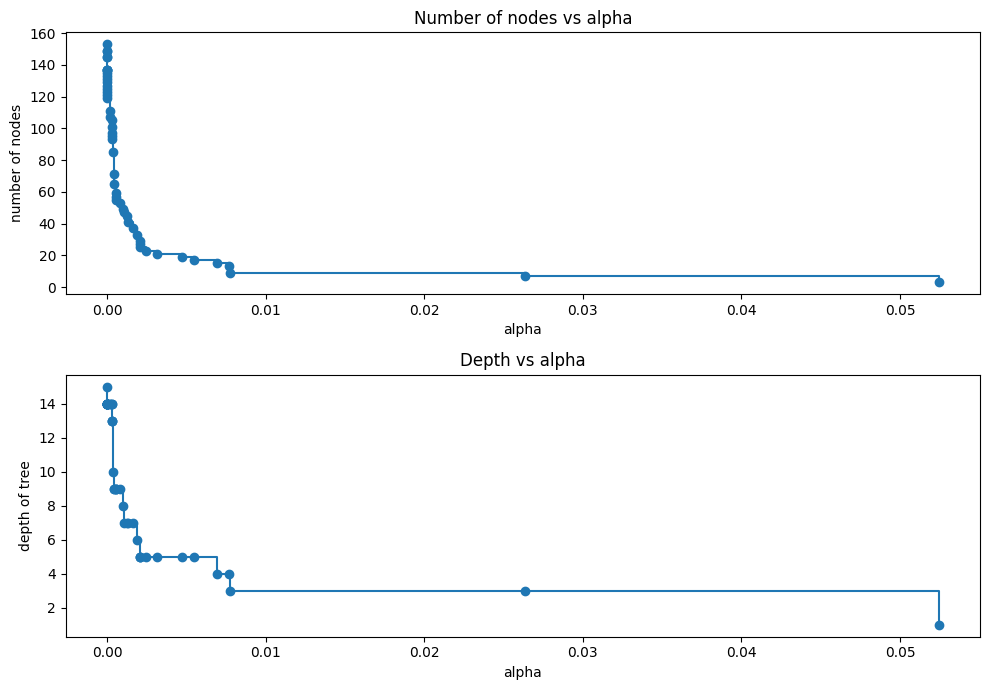

In [54]:
# Remove the last element from the list of classifiers (often the unpruned or initial tree)
clfs = clfs[:-1]

# Remove the corresponding last alpha value
ccp_alphas = ccp_alphas[:-1]

# Get the number of nodes for each pruned tree
node_counts = [clf.tree_.node_count for clf in clfs]

# Get the maximum depth for each pruned tree
depth = [clf.tree_.max_depth for clf in clfs]

# Create a figure and a set of two subplots (stacked vertically)
fig, ax = plt.subplots(2, 1, figsize=(10, 7))

# --- First Plot: Number of nodes vs alpha ---
# Plot the node count against the alpha values
ax[0].plot(ccp_alphas, node_counts, marker="o", drawstyle="steps-post")
ax[0].set_xlabel("alpha") # Label the x-axis
ax[0].set_ylabel("number of nodes") # Label the y-axis
ax[0].set_title("Number of nodes vs alpha") # Set the title

# --- Second Plot: Depth vs alpha ---
# Plot the tree depth against the alpha values
ax[1].plot(ccp_alphas, depth, marker="o", drawstyle="steps-post")
ax[1].set_xlabel("alpha") # Label the x-axis
ax[1].set_ylabel("depth of tree") # Label the y-axis
ax[1].set_title("Depth vs alpha") # Set the title

# Adjust layout to prevent plot elements from overlapping
fig.tight_layout()

In [55]:
# Initialize an empty list to store the recall scores for the training data
recall_train = []

# Loop through each decision tree classifier (clf) in the list of pruned trees (clfs)
for clf in clfs:
    # Make predictions on the training data (X_train) using the current tree
    pred_train = clf.predict(X_train)

    # Calculate the recall score using the true training labels and the predictions
    values_train = recall_score(y_train, pred_train)

    # Add the calculated recall score to the list
    recall_train.append(values_train)

In [56]:
# Initialize an empty list to store the recall scores calculated on the unseen test data.
recall_test = []

# Loop through each decision tree classifier in the 'clfs' list (the trees pruned by different alphas).
for clf in clfs:
    # Use the current classifier (clf) to make predictions on the independent test features (X_test).
    pred_test = clf.predict(X_test)

    # Calculate the recall score using the true test labels (y_test) and the predictions (pred_test).
    # This measures how well the model generalizes its ability to identify positive cases on new data.
    values_test = recall_score(y_test, pred_test)

    # Append the calculated test recall score for the current tree to the list.
    recall_test.append(values_test)

In [57]:
# Calculate the classification accuracy score for each pruned tree on the training data.
# clf.score(X_train, y_train) returns the mean accuracy: (TP + TN) / Total Samples.
train_scores = [clf.score(X_train, y_train) for clf in clfs]

# Calculate the classification accuracy score for each pruned tree on the independent test data.
# This score indicates how well each model generalizes to new, unseen data.
test_scores = [clf.score(X_test, y_test) for clf in clfs]

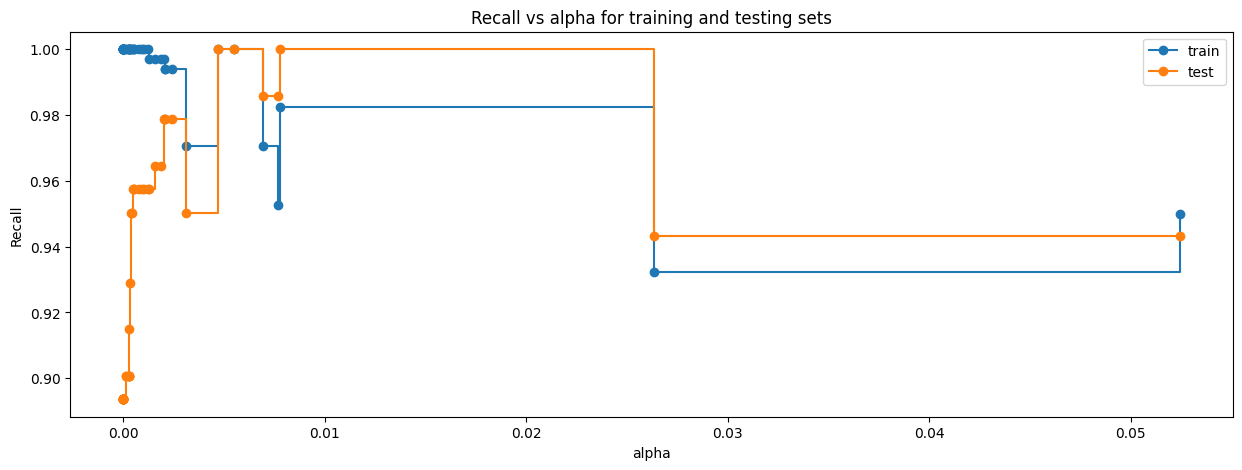

In [58]:
# Create a figure and an axes object for the plot, with a specified size
fig, ax = plt.subplots(figsize=(15, 5))

# Set the label for the x-axis (the pruning parameter)
ax.set_xlabel("alpha")

# Set the label for the y-axis (the performance metric)
ax.set_ylabel("Recall")

# Set the title of the plot
ax.set_title("Recall vs alpha for training and testing sets")

# Plot the training recall scores against the alpha values
ax.plot(
    ccp_alphas,  # x-axis data: the list of alpha values
    recall_train, # y-axis data: recall scores on the training set
    marker="o", # Use circles for data points
    label="train", # Label this line for the legend
    drawstyle="steps-post", # Connect points with a step-style line
)

# Plot the test recall scores against the alpha values
ax.plot(
    ccp_alphas, # x-axis data
    recall_test, # y-axis data: recall scores on the test set
    marker="o", # Use circles for data points
    label="test", # Label this line for the legend
    drawstyle="steps-post", # Connect points with a step-style line
)

# Display the legend to identify the training and test lines
ax.legend()

# Display the generated plot
plt.show()

In [59]:
# Find the index of the highest recall score achieved on the test set.
# np.argmax returns the index corresponding to the maximum value in the array.
index_best_model = np.argmax(recall_test)

# Use the found index to select the corresponding Decision Tree Classifier
# from the 'clfs' list. This is the model that performed best on unseen data
# based on the recall metric.
best_model = clfs[index_best_model]

# Print the details of the best performing model. This output will typically
# show the hyperparameters used by the Decision Tree, including the optimal
# 'ccp_alpha' value that resulted in this specific pruning.
print(best_model)

DecisionTreeClassifier(ccp_alpha=np.float64(0.004708432579818331),
                       class_weight='balanced', random_state=1)


In [60]:
# Initialize the Decision Tree Classifier model
dt_model = DecisionTreeClassifier(
    # A pruning parameter used to simplify the tree and prevent overfitting
    ccp_alpha=np.float64(0.004008680486241742),

    # Automatically adjusts weights for classes that are not represented equally (imbalanced data)
    class_weight='balanced',

    # Sets a seed to ensure the results are the same every time the code runs
    random_state=1
)

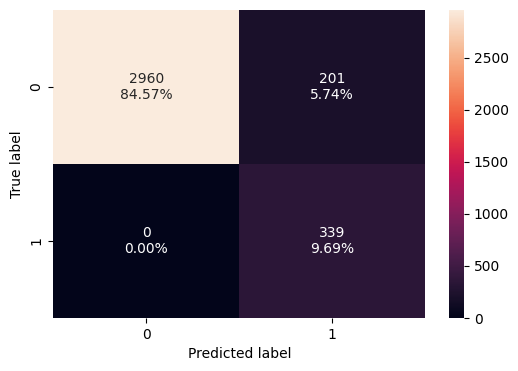

In [61]:
# Save the best performing model found earlier to a new variable
model4 = best_model

# Call a custom function to generate the confusion matrix using the training data
# This helps visualize where the model is making correct predictions vs. errors
confusion_matrix_sklearn(model4, X_train, y_train)

In [62]:
# Calculate performance metrics (like accuracy, recall, precision) using the training data
decision_tree_post_perf_train = model_performance_classification_sklearn(
    model4, X_train, y_train
)

# Display the performance results calculated above
decision_tree_post_perf_train

,Accuracy,Recall,Precision,F1
0,0.942571,1.0,0.627778,0.771331


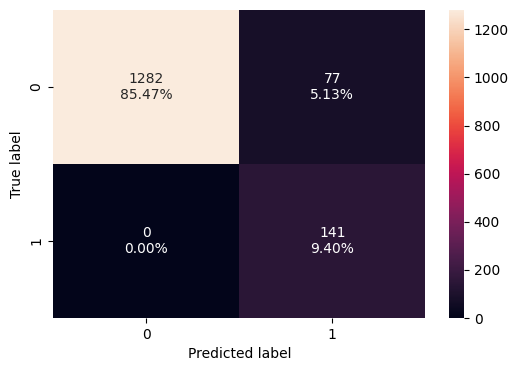

In [63]:
# Plot confusion matrix for the tuned Decision Tree (model4) on the TEST set.
# This shows:
#   - Top-left: True Negatives (TN)
#   - Top-right: False Positives (FP)
#   - Bottom-left: False Negatives (FN)
#   - Bottom-right: True Positives (TP)
# Counts and percentages are displayed in each cell to help assess model risk.
confusion_matrix_sklearn(model4, X_test, y_test)


In [64]:
# Calculate performance metrics (like accuracy, precision, recall) using the unseen test data
decision_tree_post_test = model_performance_classification_sklearn(
    model4, X_test, y_test
)

# Display the performance results for the test set
decision_tree_post_test

,Accuracy,Recall,Precision,F1
0,0.948667,1.0,0.646789,0.785515


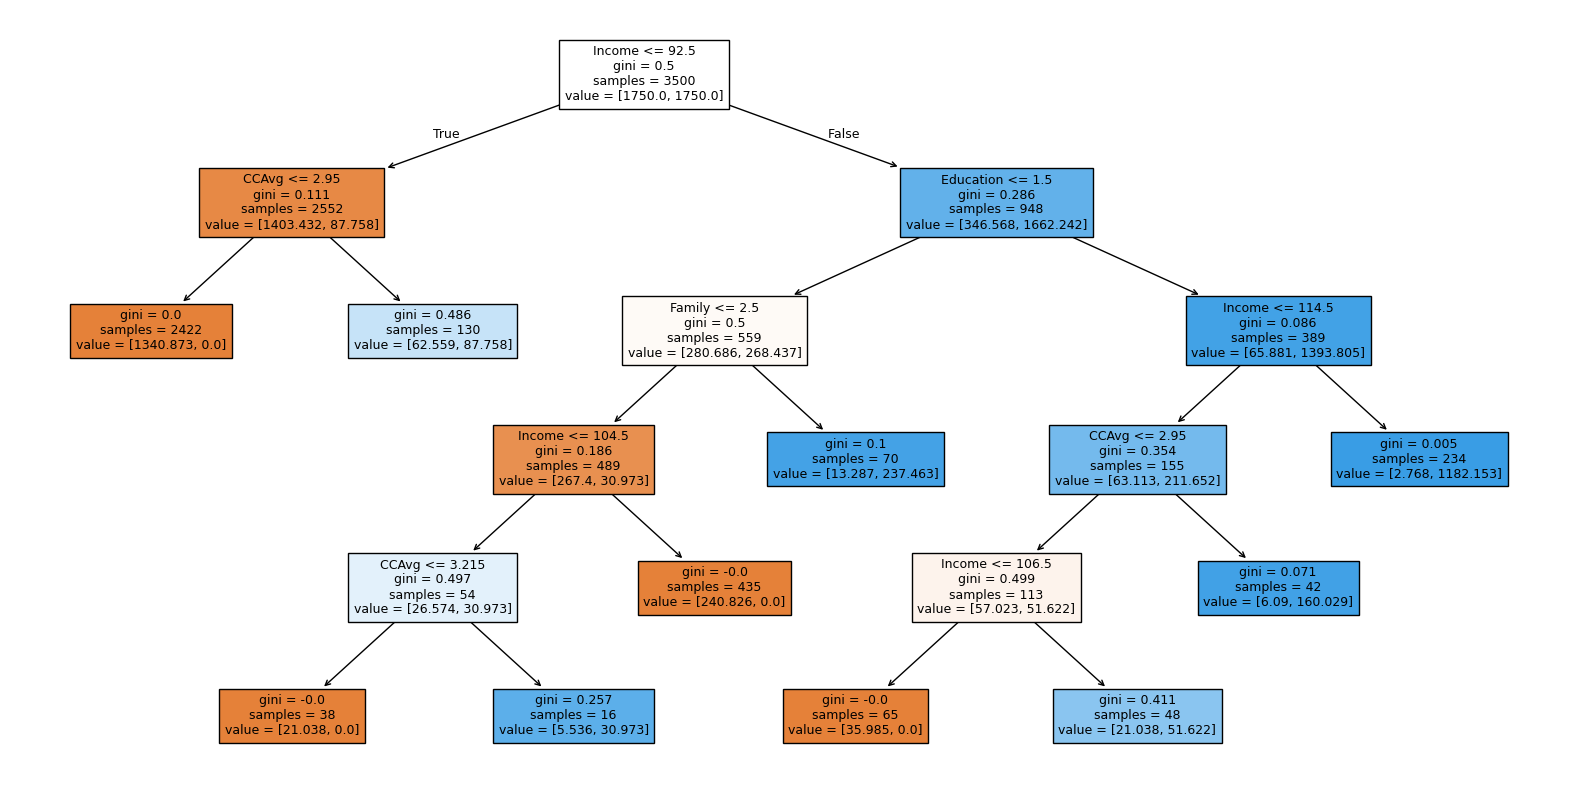

In [65]:
# Create a large figure (canvas) size so the tree is readable
plt.figure(figsize=(20, 10))

# Visualize the decision tree structure
out = tree.plot_tree(
    model4,
    feature_names=feature_names, # Add specific names to the features for clarity
    filled=True,                 # Color the nodes to indicate the majority class
    fontsize=9,                  # Set the text size
    node_ids=False,
    class_names=None,
)

# Loop through the plot elements to customize the appearance of the arrows
for o in out:
    arrow = o.arrow_patch
    if arrow is not None:
        # Change the arrow outline color to black for better contrast
        arrow.set_edgecolor("black")
        # Set the thickness of the arrow lines
        arrow.set_linewidth(1)

# Display the final plot
plt.show()

In [66]:
# Text report showing the rules of a decision tree -

print(tree.export_text(model4, feature_names=feature_names, show_weights=True))

|--- Income <= 92.50
|   |--- CCAvg <= 2.95
|   |   |--- weights: [1340.87, 0.00] class: 0
|   |--- CCAvg >  2.95
|   |   |--- weights: [62.56, 87.76] class: 1
|--- Income >  92.50
|   |--- Education <= 1.50
|   |   |--- Family <= 2.50
|   |   |   |--- Income <= 104.50
|   |   |   |   |--- CCAvg <= 3.21
|   |   |   |   |   |--- weights: [21.04, 0.00] class: 0
|   |   |   |   |--- CCAvg >  3.21
|   |   |   |   |   |--- weights: [5.54, 30.97] class: 1
|   |   |   |--- Income >  104.50
|   |   |   |   |--- weights: [240.83, 0.00] class: 0
|   |   |--- Family >  2.50
|   |   |   |--- weights: [13.29, 237.46] class: 1
|   |--- Education >  1.50
|   |   |--- Income <= 114.50
|   |   |   |--- CCAvg <= 2.95
|   |   |   |   |--- Income <= 106.50
|   |   |   |   |   |--- weights: [35.99, 0.00] class: 0
|   |   |   |   |--- Income >  106.50
|   |   |   |   |   |--- weights: [21.04, 51.62] class: 1
|   |   |   |--- CCAvg >  2.95
|   |   |   |   |--- weights: [6.09, 160.03] class: 1
|   |   |--- In

In [67]:
# Extract the importance score for each feature from the model
importances = model4.feature_importances_

# Get the indices that sort the features by importance (from lowest to highest)
# This is usually done to prepare the data for a plot
indices = np.argsort(importances)

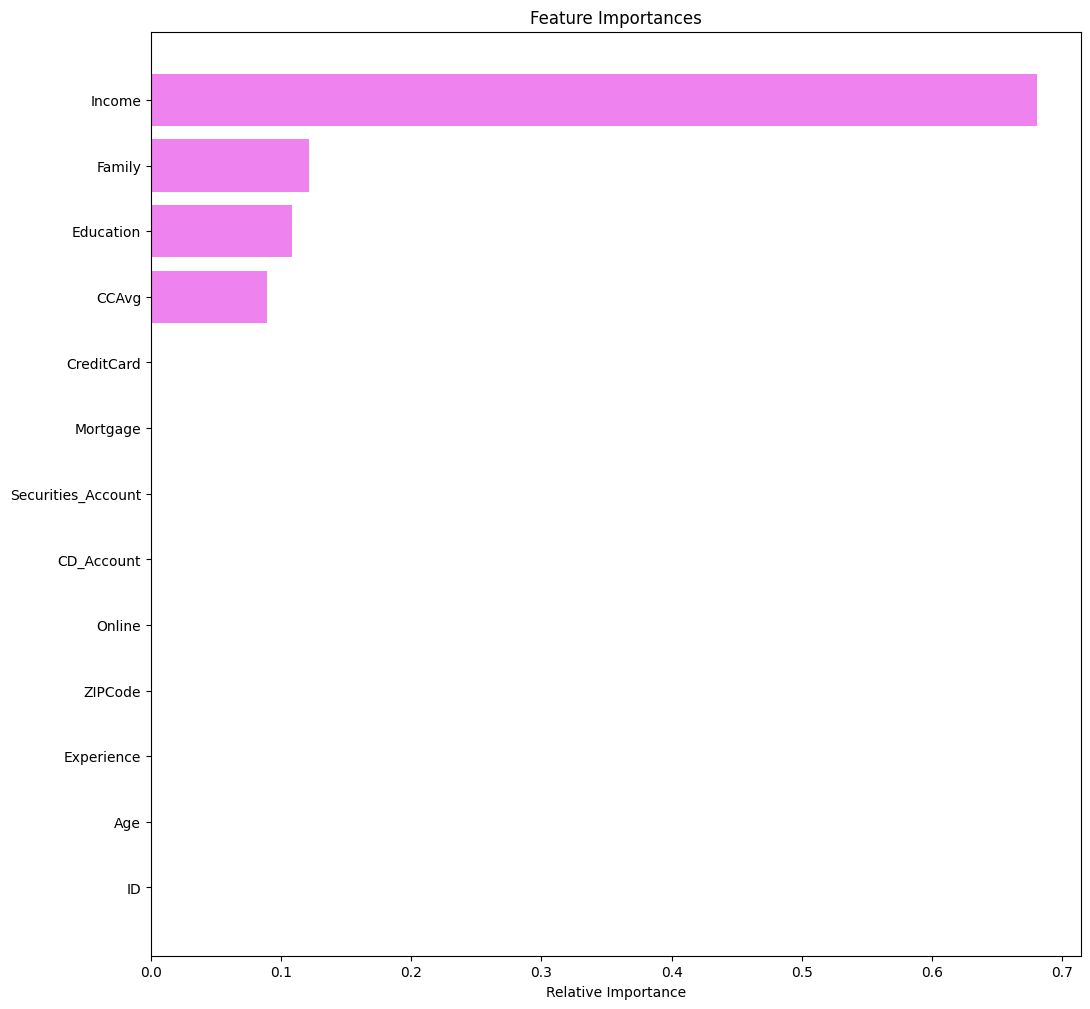

In [68]:
# Create a plot with specific dimensions
plt.figure(figsize=(12, 12))

# Set a title to the chart
plt.title("Feature Importances")

# Create a horizontal bar chart using the sorted importance values
# 'barh' stands for bar-horizontal
plt.barh(range(len(indices)), importances[indices], color="violet", align="center")

# Label the Y-axis ticks with the feature names (sorted to match the bars)
plt.yticks(range(len(indices)), [feature_names[i] for i in indices])

# Label the X-axis to indicate what the bar length represents
plt.xlabel("Relative Importance")

# Display the final bar chart
plt.show()

###Comparison of Models and Final Model Selection

In [69]:
# training performance comparison

# Combine the training results from four different models into a single DataFrame
models_train_comp_df = pd.concat(
    [
        # Transpose (.T) the results so metrics align side-by-side
        decision_tree_default_perf_train.T,
        decision_tree_perf_train.T,
        decision_tree_tune_perf_train.T,
        decision_tree_post_perf_train.T,
    ],
    # align them horizontally
    axis=1,
)

# Rename the columns to clearly label each model type
models_train_comp_df.columns = [
    "Decision Tree (sklearn default)",
    "Decision Tree with class_weight",
    "Decision Tree (Pre-Pruning)",
    "Decision Tree (Post-Pruning)",
]

print("Training performance comparison:")

# Display the final comparison table
models_train_comp_df

Training performance comparison:


,Decision Tree (sklearn default),Decision Tree with class_weight,Decision Tree (Pre-Pruning),Decision Tree (Post-Pruning)
Accuracy,1.0,1.0,0.959714,0.942571
Recall,1.0,1.0,0.964602,1.000000
Precision,1.0,1.0,0.717105,0.627778
F1,1.0,1.0,0.822642,0.771331


In [70]:
# testing performance comparison

# Combine the test results from four different models into one DataFrame
models_test_comp_df = pd.concat(
    [
        # Transpose (.T) each result to arrange metrics as rows and models as columns
        decision_tree_default_perf_test.T,
        decision_tree_perf_test.T,
        decision_tree_tune_perf_test.T,
        decision_tree_post_test.T,
    ],
    # Join them side-by-side
    axis=1,
)

# Rename the columns to identify which model configuration each column represents
models_test_comp_df.columns = [
    "Decision Tree (sklearn default)",
    "Decision Tree with class_weight",
    "Decision Tree (Pre-Pruning)",
    "Decision Tree (Post-Pruning)",
]

print("Test set performance comparison:")

# Display the final comparison table
models_test_comp_df

Test set performance comparison:


,Decision Tree (sklearn default),Decision Tree with class_weight,Decision Tree (Pre-Pruning),Decision Tree (Post-Pruning)
Accuracy,0.982667,0.977333,0.958000,0.948667
Recall,0.921986,0.893617,0.964539,1.000000
Precision,0.896552,0.868966,0.701031,0.646789
F1,0.909091,0.881119,0.811940,0.785515


#### Observations from Test set performance comparison:
*   **Decision Tree (sklearn default)** has the highest accuracy and F1-score among all models, with a recall of 0.92 and precision of 0.89.
*   **Decision Tree (Pre-Pruning)** shows a good balance, with a recall of 0.96 and precision of 0.70. Its accuracy is slightly lower than the default model, but it manages to capture a high percentage of positive cases.
*   **Decision Tree with class_weight** performs slightly worse than the default model in terms of recall and F1-score, suggesting that simply balancing class weights might not be enough to improve performance on the minority class significantly in this case.
*   **Decision Tree (Post-Pruning)** achieves a perfect recall of 1.0, meaning it identifies all actual personal loan takers. However, this comes at the cost of the lowest precision (0.64) and accuracy, indicating a higher number of false positives. This model is useful if minimizing false negatives is the absolute priority, even at the expense of false positives.

**Overall:** For this problem, where recall is important, the **Decision Tree (Pre-Pruning)** model seems to strike a good balance between identifying personal loan takers (high recall) and maintaining a reasonable precision and accuracy. The **Decision Tree (Post-Pruning)** also achieves a perfect recall, which could be considered if the business impact of false negatives is extremely high and can tolerate more false positives.

### Conclusion and Recommendations

### Conclusions:
* Only about 9–10% of customers actually took the personal loan, which means very few people said “yes.” Because of this, it’s important for our model to correctly find these few interested customers.

* Customers who are more likely to take a personal loan usually have:

  * Higher incomes

  * Higher credit card spending (CCAvg)

  * Higher education levels

  * CD accounts or online banking usage

* These factors show up again and again as strong signals of loan interest.

* The first Decision Tree model fit the training data too perfectly, which means it memorized the data instead of learning patterns. This is called overfitting, and it usually performs worse on new data.

* After trying different Decision Tree settings:

  * Pre-pruning (limiting the size of the tree)

  * Post-pruning (cutting unnecessary branches) both helped the model avoid overfitting and perform better on unseen data.

* When tested on new data:

  * The default tree had the best overall accuracy, but missed some customers who would take a loan (recall ~0.92).

  * The pre-pruned tree caught more of the real loan-takers (recall ~0.96) with only a small drop in accuracy.

  * The post-pruned tree caught all loan-takers (recall = 1.0), but made many wrong predictions (low precision).

* Because missing potential customers (false negatives) is more costly for the bank than contacting a few extra people, the pre-pruned tree is the best balance.
* It finds most of the customers who would accept the loan while keeping the number of wrong predictions at a reasonable level.

### Recommendations:

* Use the Pre-Pruned Decision Tree as the Final Model

  * Deploy the pre-pruned model to score all customers.

  * Focus marketing efforts on customers with the highest predicted likelihood of accepting a personal loan.


* Prioritize High-Potential Customer Segments

  * Target customers who consistently show stronger interest in personal loans:

    * High income

    * Higher credit card spending (CCAvg)

    * Higher education levels

    * Active online banking users

    * Customers with CD or investment accounts
* Marketing Approach
  * Online-active customers: email, SMS, app notifications to customers

  * Less online customers: Branch follow-ups, and frequent relationship manager calls to be executed.
* Improving the Loan Offer & Messaging  
  * Highlight quick approval, simple process, and competitive interest rates.
  * Offer special benefits like better interest rates or pre-approved offers to customers who already hold CD or investment accounts.

